In [1]:
import os
import glob
import h5py
import numpy as np
import torch

from typing import List, Dict, Optional
import matplotlib.pyplot as plt

from __future__ import annotations

import argparse
from pathlib import Path

In [2]:
from src.utils.fourier_utils import create_wavenumbers, compute_derivative, compute_laplacian

kx, ky, kx_first, ky_first = create_wavenumbers(128,128,1,1,"cpu")

In [3]:
def lowpass_filter(field: torch.Tensor, cutoff_min=0.0, cutoff_max=1.0) -> torch.Tensor:
    nx, ny = field.shape[-2:]
    freq_dtype = torch.float32
    fx = torch.fft.fftfreq(nx, device=field.device, dtype=freq_dtype).reshape(
        1, 1, nx, 1
    )
    fy = torch.fft.rfftfreq(ny, device=field.device, dtype=freq_dtype).reshape(
        1, 1, 1, ny // 2 + 1
    )

    mask = ((fx.square() + fy.square()).sqrt() <= cutoff_max) * ((fx.square() + fy.square()).sqrt() >= cutoff_min)

    field_h = torch.fft.rfftn(field, dim=(-2, -1))
    while mask.ndim > field_h.ndim:
        mask = mask.squeeze(0)
    return torch.fft.irfftn(field_h * mask, s=(nx, ny), dim=(-2, -1))

In [4]:
def minmax_norm(A):
    min_val = torch.min(A)
    max_val = torch.max(A)
    return (A-min_val)/(max_val-min_val) * 2 - 1

In [5]:
def laplacian(field):
    return torch.fft.irfftn(compute_laplacian(torch.fft.rfftn(field, dim=[0,1]), kx[0][0], ky[0][0]), dim=[0,1], s=(128,128))
    
def ddx(field):
    return torch.fft.irfftn(compute_derivative(torch.fft.rfftn(field, dim=[0,1]), kx_first[0][0]), dim=[0,1], s=(128,128))
    
def ddy(field):
    return torch.fft.irfftn(compute_derivative(torch.fft.rfftn(field, dim=[0,1]), ky_first[0][0]), dim=[0,1], s=(128,128))

# Calculates the right hand side of the induction equation
def rhs(A, psi, dt):
    ux_pred = -ddy(psi)
    uy_pred = ddx(psi)
    
    A_x = ddx(A)
    A_y = ddy(A)
    lap_A = laplacian(A)
    
    return (0.0013333333333 * lap_A - (ux_pred*A_x + uy_pred*A_y))
    # return (0.001 * lap_A - (ux_pred*A_x + uy_pred*A_y))

In [6]:
def reconstruct(initial_A, psi, freq_max=0.2):
    As = [initial_A]
    A = initial_A
    
    n=8
    dt = 0.04/n
    
    for i in range(n*len(psi)):
        i1 = i//n
        i2 = min(i//n + 1, len(psi)-1)
        psi_interp = psi[i1]*(i%n)/n + psi[i2]*(1 - (i%n)/n)

        k1 = rhs(A, psi_interp, dt) * dt
        k2 = rhs(A + 0.5*dt*k1, psi_interp, dt) * dt
        k3 = rhs(A + 0.5*dt*k2, psi_interp, dt) * dt
        k4 = rhs(A + dt*k3, psi_interp, dt) * dt
        A = A + (k1 + 2*k2 + 2*k3 + k4)/6
        A = lowpass_filter(A, cutoff_max=0.16)
        if i % n == n-1:
            As.append(A)
    return np.array(As[:-1])

In [7]:
# Re 750
std_psi = 0.021676693253362907
std_A = 0.0009381390596884123

# # Re 1000
# std_psi = 0.022428618611113046
# std_A = 0.0009708260721581244

In [8]:
def psi_to_v(psi):
    pred_psi_h = torch.fft.rfftn(psi, dim=[1,2])
    vy_pred = torch.fft.irfftn(compute_derivative(pred_psi_h, kx_first), dim=[-2,-1])[0]
    vx_pred = torch.fft.irfftn(compute_derivative(pred_psi_h, ky_first), dim=[-2,-1])[0]
    vy_pred = lowpass_filter(vy_pred, cutoff_max=0.15)
    vx_pred = lowpass_filter(vx_pred, cutoff_max=0.15)
    return vx_pred, vy_pred

In [9]:
import math

def loss(pred, target):
    return (torch.mean((pred-target)**2)/torch.mean(target**2))

In [36]:
re = 1000
errs = []
total_l2 = 0

data = []
for i in range(1,2):
    pred_psi = torch.load(f"results/x_data_2_Re{re}_{i}.pt")[:,:,0].reshape([-1,128,128]).cpu() * std_psi
    vx_pred, vy_pred = psi_to_v(pred_psi)

    pred_psi_2 = torch.load(f"results/pred_data_2_Re{re}_{i}.pt")[:,:,0].reshape([-1,128,128]).cpu() *std_psi
    vx_pred_2, vy_pred_2 = psi_to_v(pred_psi_2)

    psi = torch.load(f"results/y_data_2_Re{re}_{i}.pt")[:,:,0].reshape([-1,128,128]).cpu() * std_psi
    min_psi, max_psi = torch.min(psi), torch.max(psi)
    vx, vy = psi_to_v(psi)

    vy = minmax_norm(vy)
    vy_pred = minmax_norm(vy_pred)
    vy_pred_2 = minmax_norm(vy_pred_2)
    vx = minmax_norm(vx)
    vx_pred = minmax_norm(vx_pred)
    vx_pred_2 = minmax_norm(vx_pred_2)

    pred_v = torch.cat([vy_pred.unsqueeze(-1), vx_pred.unsqueeze(-1)], dim=3)
    v = torch.cat([vy.unsqueeze(-1), vx.unsqueeze(-1)], dim=3)

    pred_v_2 = torch.cat([vy_pred_2.unsqueeze(-1), vx_pred_2.unsqueeze(-1)], dim=3)

    pred_A_0 = torch.load(f"results/x_data_2_Re{re}_{i}.pt")[:,:,1].reshape([-1,128,128]).cpu() * std_A
    pred_A = torch.load(f"results/pred_data_2_Re{re}_{i}.pt")[:,:,1].reshape([-1,128,128]).cpu() * std_A
    A = torch.load(f"results/y_data_2_Re{re}_{i}.pt")[:,:,1].reshape([-1,128,128]).cpu() * std_A
    pred_A_recon = torch.tensor(reconstruct(A[0], pred_psi_2))
    # pred_A_recon = pred_A

    data.append([psi,A])
    
    A = minmax_norm(A)
    pred_A = minmax_norm(pred_A)
    pred_A_recon = minmax_norm(pred_A_recon)
    
    psi = minmax_norm(psi)
    pred_psi = minmax_norm(pred_psi)
    pred_psi_2 = minmax_norm(pred_psi_2)

    pred = torch.cat([pred_v_2,pred_A_recon.unsqueeze(-1)], dim=3)
    target = torch.cat([v,A.unsqueeze(-1)], dim=3)

    errs.append([loss(pred_psi,psi), loss(pred_psi_2,psi), loss(pred_v,v), loss(pred_v_2,v), loss(pred_A_recon,A), loss(pred_A,A), loss(pred,target)])
    print(loss(pred_psi,psi), loss(pred_psi_2,psi), loss(pred_v,v), loss(pred_v_2,v), loss(pred_A_recon,A), loss(pred_A,A), loss(pred,target))
    total_l2 += (torch.mean((pred-target)**2)/torch.mean(target**2))

tensor(0.1047) tensor(0.1039) tensor(0.1490) tensor(0.1392) tensor(0.1537) tensor(0.3629) tensor(0.1450)


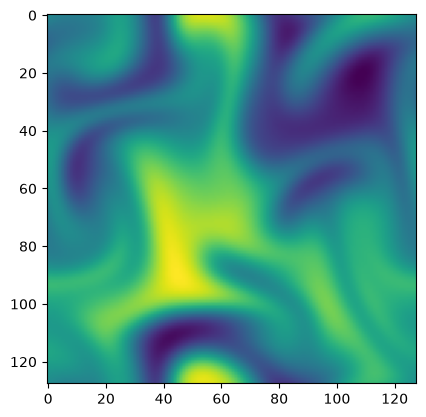

In [44]:
plt.imshow(pred_A_recon[25])

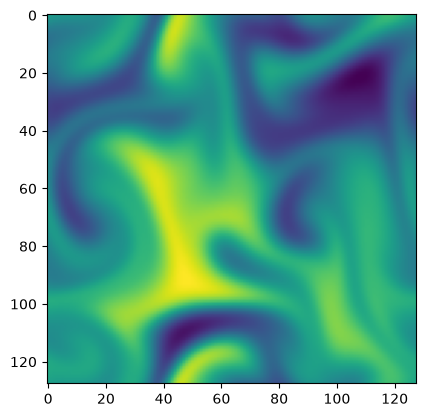

In [42]:
plt.imshow(A[25])

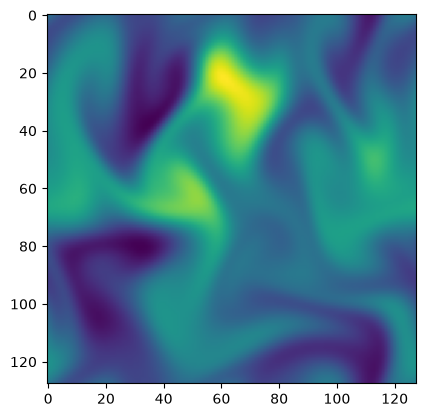

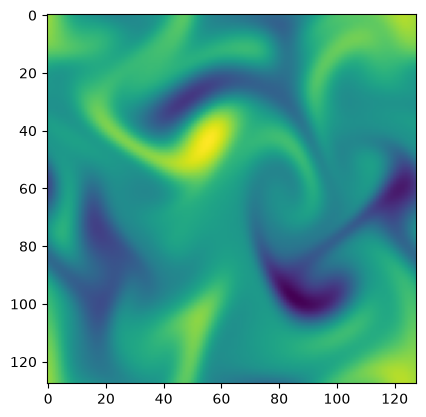

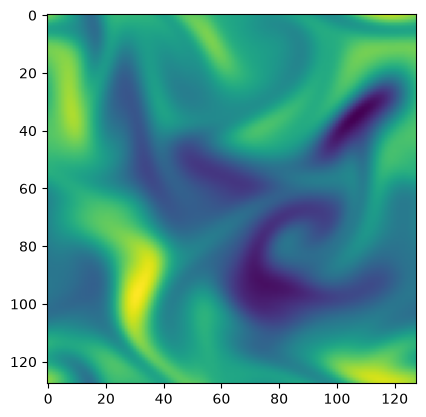

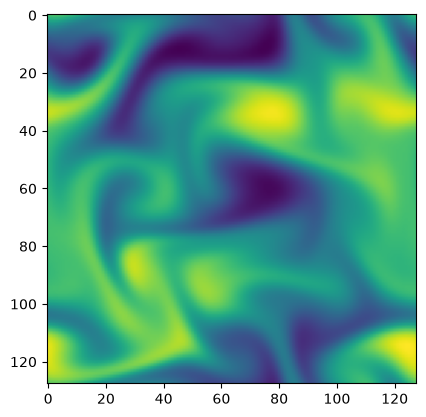

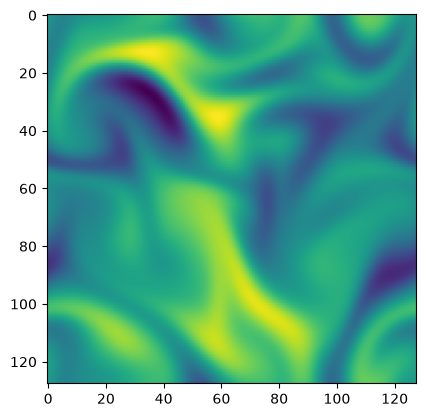

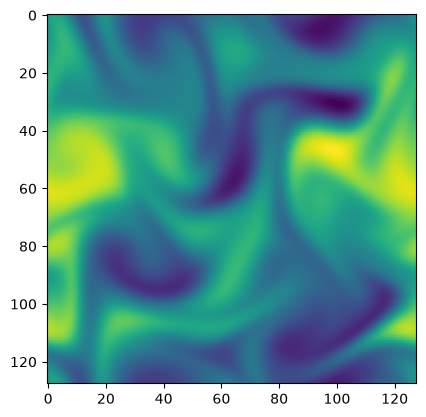

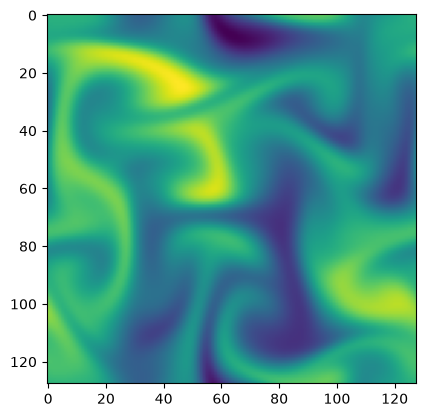

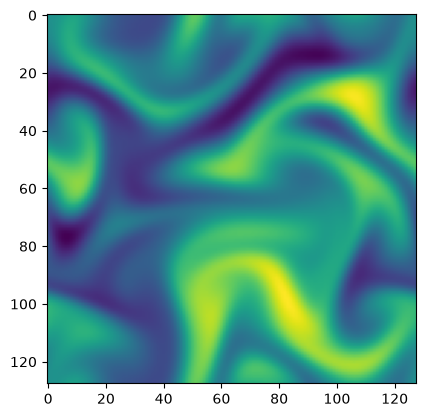

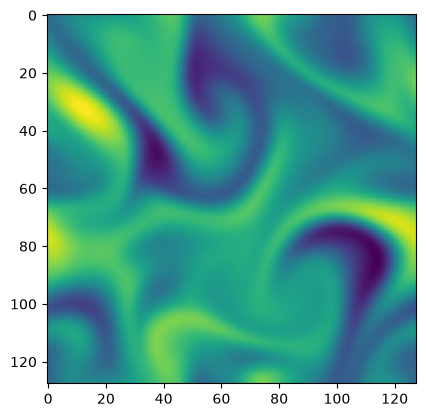

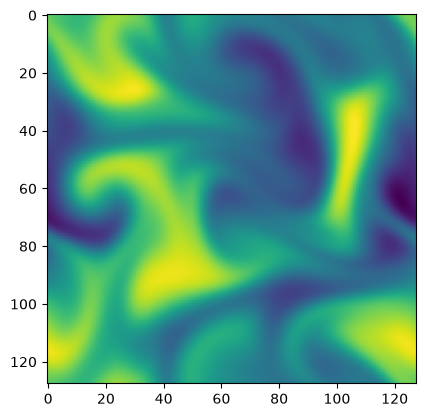

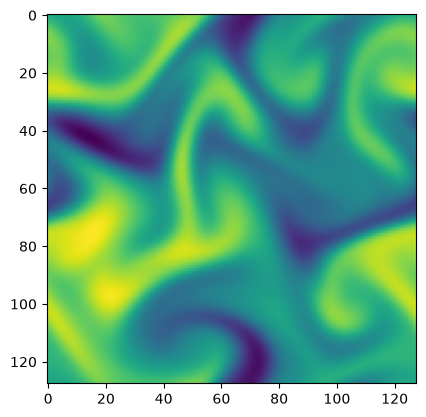

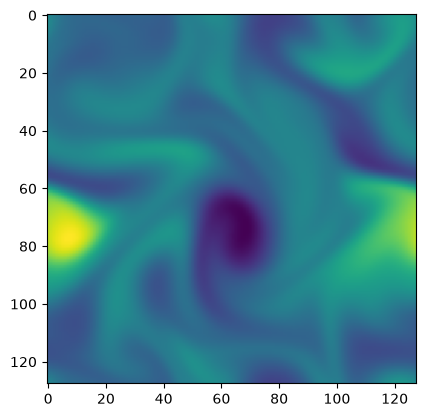

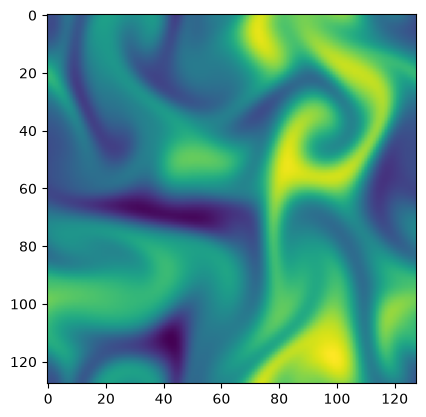

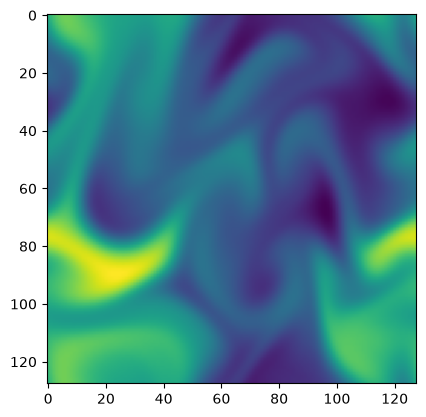

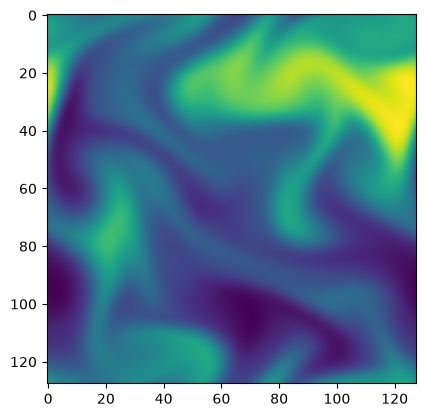

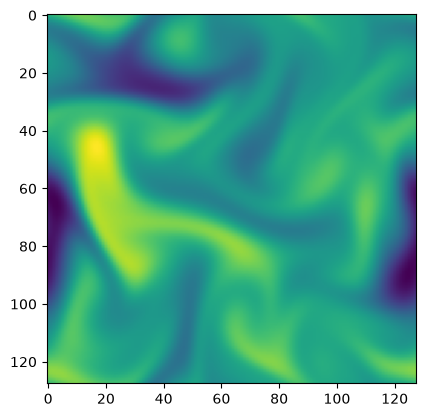

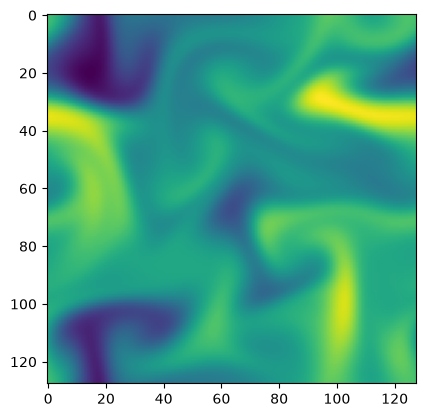

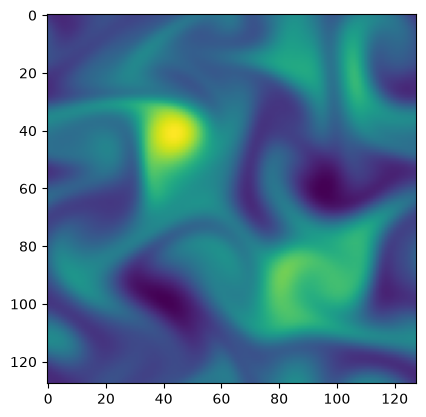

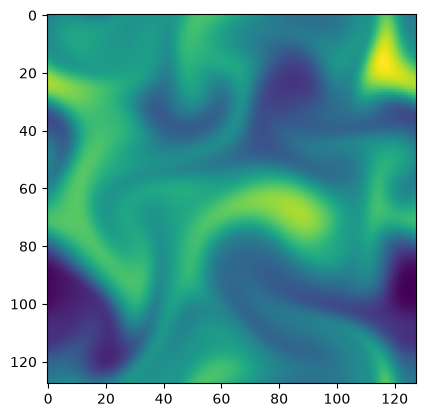

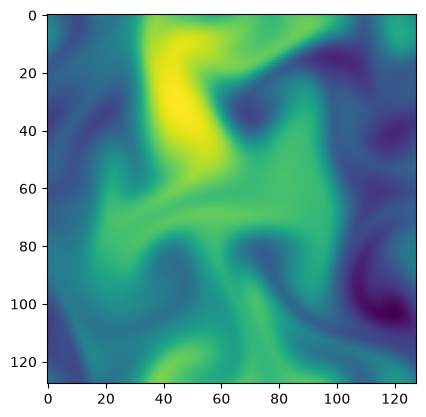

FileNotFoundError: [Errno 2] No such file or directory: 'results/y_data_3_Re1000_20.pt'

In [47]:
for i in range(20):
    psi = torch.load(f"results/y_data_3_Re{re}_{i}.pt")[:,:,1].reshape([-1,128,128]).cpu() * std_psi
    plt.imshow(psi[25])
    plt.show()